# Part II · Notebook 02 — X1 & X2: stronger adversaries

Part I used black-box attacks that need no knowledge of the generator, so its privacy results are a *lower bound*.
Here we use three stronger attack families:

1. **Record-targeted shadow-model membership inference** (Stadler et al. 2022; Houssiau et al. 2022). The attacker knows
   the generator type, trains it many times on datasets that do / do not contain a chosen target, and learns to recognise
   the target's footprint in the synthetic data (counting queries + distances).
2. **Vulnerable-record targeting** (Meeus et al. 2023): targets are chosen as the most isolated records.
3. **Empirical differential-privacy audit** of MST: the attack's false-positive and false-negative rates on fresh
   releases give a statistical lower bound on the ε the implementation actually provides (Jagielski et al. 2020).
4. **Linear reconstruction** of a secret attribute for all training users (Annamalai et al. 2024).

Hypotheses H6–H9 (Notebook 00) are tested in Notebook 05.

In [1]:
import os, time, json, gc, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from joblib import Parallel, delayed
import sdaudit as sa
QUICK = os.environ.get("QUICK", "0") == "1"
if QUICK: sa.CFG.update(ctgan_epochs=3, tvae_epochs=3, ddpm_steps=50, ar_steps=30)
OUT = "outputs2"; os.makedirs(f"{OUT}/tables", exist_ok=True); os.makedirs(f"{OUT}/figures", exist_ok=True)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1); plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
T0 = time.time()
df, meta = sa.load("adult")
meta["_qbins"] = {c: np.unique(np.quantile(df[c], np.linspace(0.1, 0.9, 9))) for c in meta["num"]}
N_SHADOW = 500                      # records per synthetic-data training set
NT, NE = (150, 60) if not QUICK else (8, 8)   # shadow training releases / evaluation releases per target (cheap generators)

## 1. Target selection
Vulnerability = mean distance to the 5 nearest other records in a 5,000-record reference sample (Meeus et al. 2023).
The 5 most vulnerable records and 5 random records become targets.

In [2]:
rs = np.random.RandomState(7)
ref = df.iloc[rs.choice(len(df), 5000, replace=False)].reset_index(drop=True)
v = sa.vulnerability(ref, meta)
vul_idx = np.argsort(-v)[:5]; rnd_idx = rs.choice(np.setdiff1d(np.arange(len(ref)), vul_idx), 5, replace=False)
TARGETS = [("vulnerable", i) for i in vul_idx] + [("random", i) for i in rnd_idx]
pool = df.drop(index=df.index[df.apply(tuple, axis=1).isin(ref.iloc[[i for _, i in TARGETS]].apply(tuple, axis=1))]).reset_index(drop=True)
display(ref.iloc[[i for _, i in TARGETS]].assign(kind=[k for k, _ in TARGETS], vulnerability=v[[i for _, i in TARGETS]].round(3)))

def subsets_for(i, k=20):
    r = np.random.RandomState(1000 + int(i)); cols = [c for c in ref.columns]
    return [list(r.choice(cols, r.randint(1, 4), replace=False)) for _ in range(k)]

,age,workclass,education,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,kind,vulnerability
4482,46.0,Self-emp-inc,Assoc-voc,Divorced,Exec-managerial,Unmarried,Asian-Pac-Islander,Female,0.0,0.0,63.0,Thailand,<=50K,vulnerable,2.008
4571,45.0,Federal-gov,Assoc-acdm,Divorced,Adm-clerical,Unmarried,Asian-Pac-Islander,Male,0.0,2080.0,40.0,Philippines,<=50K,vulnerable,1.983
2643,38.0,Federal-gov,Prof-school,Never-married,Prof-specialty,Not-in-family,Asian-Pac-Islander,Female,99999.0,0.0,57.0,Canada,>50K,vulnerable,1.972
2884,42.0,Private,Assoc-acdm,Married-spouse-absent,Exec-managerial,Unmarried,Asian-Pac-Islander,Female,0.0,0.0,31.0,Laos,<=50K,vulnerable,1.950
1702,46.0,Self-emp-not-inc,HS-grad,Married-spouse-absent,Craft-repair,Not-in-family,Asian-Pac-Islander,Male,0.0,0.0,45.0,India,>50K,vulnerable,1.896
3807,34.0,Local-gov,HS-grad,Never-married,Adm-clerical,Own-child,White,Female,0.0,0.0,40.0,United-States,<=50K,random,1.003
3451,52.0,Private,HS-grad,Divorced,Machine-op-inspct,Own-child,Black,Female,0.0,0.0,35.0,United-States,<=50K,random,0.880
3223,54.0,Private,Preschool,Married-civ-spouse,Craft-repair,Husband,Asian-Pac-Islander,Male,0.0,0.0,40.0,India,<=50K,random,1.420
3808,36.0,Private,Masters,Never-married,Exec-managerial,Not-in-family,White,Male,0.0,0.0,15.0,United-States,<=50K,random,0.614
3813,58.0,Private,HS-grad,Widowed,Adm-clerical,Unmarried,White,Female,0.0,0.0,40.0,United-States,<=50K,random,0.181


## 2. Shadow-model attacks
10 targets for Independent, Gaussian copula and CART; 4 targets (2 vulnerable + 2 random) for TVAE, whose fits are slower.
Each (target, generator) uses 150 shadow releases to train the attack and 60 fresh releases (30 with, 30 without the target) to evaluate it; for TVAE 50 and 30.

In [3]:
def one(gname, kind, i, nt, ne):
    t = ref.iloc[i]; r = sa.shadow_attack(sa.GENERATORS[gname], pool, t, meta, N_SHADOW, nt, ne, seed=int(i) % 997, subsets=subsets_for(i))
    return dict(generator=gname, kind=kind, target=int(i), vulnerability=float(v[i]), auc=r["auc"], acc=r["acc"], bb_auc=r["bb_auc"])

SH_PATH = f"{OUT}/tables/X1_shadow.csv"; sh = []
plan = [(g, TARGETS) for g in ["Independent", "GaussianCopula", "CART"]] + [("TVAE", TARGETS[:2] + TARGETS[5:7])]
for g, tg in plan:
    t0 = time.time()
    nt, ne = (NT, NE) if g != "TVAE" else ((50, 30) if not QUICK else (6, 6))
    res = Parallel(n_jobs=2 if g != "TVAE" else 1)(delayed(one)(g, k, i, nt, ne) for k, i in tg)
    sh += res; pd.DataFrame(sh).to_csv(SH_PATH, index=False)
    print(f"{g:<15} targets={len(tg)} mean shadow AUC={np.mean([r['auc'] for r in res]):.3f} black-box AUC={np.mean([r['bb_auc'] for r in res]):.3f} | {time.time()-t0:.0f}s", flush=True)
SH = pd.DataFrame(sh)
SH.groupby(["generator", "kind"])[["auc", "bb_auc", "acc"]].mean().round(3)

Independent     targets=10 mean shadow AUC=0.599 black-box AUC=0.554 | 30s


GaussianCopula  targets=10 mean shadow AUC=0.567 black-box AUC=0.544 | 605s


CART            targets=10 mean shadow AUC=0.694 black-box AUC=0.699 | 97s


TVAE            targets=4 mean shadow AUC=0.436 black-box AUC=0.548 | 1217s


auc  bb_auc    acc
generator      kind                            
CART           random      0.599   0.656  0.593
               vulnerable  0.790   0.743  0.733
GaussianCopula random      0.477   0.476  0.470
               vulnerable  0.656   0.612  0.637
Independent    random      0.570   0.578  0.543
               vulnerable  0.629   0.530  0.593
TVAE           random      0.378   0.550  0.417
               vulnerable  0.493   0.546  0.567

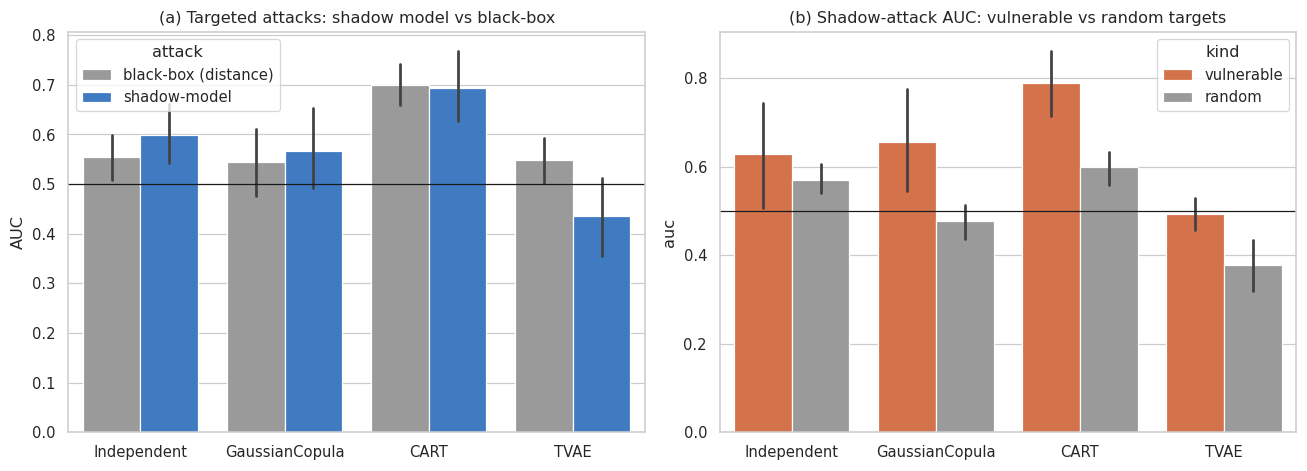

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
m = SH.melt(id_vars=["generator", "kind"], value_vars=["bb_auc", "auc"], var_name="attack", value_name="AUC").replace({"bb_auc": "black-box (distance)", "auc": "shadow-model"})
sns.barplot(data=m, x="generator", y="AUC", hue="attack", ax=axes[0], errorbar=("ci", 95), palette=["#9a9a9a", "#2a78d6"])
axes[0].axhline(0.5, c="k", lw=0.8); axes[0].set_title("(a) Targeted attacks: shadow model vs black-box"); axes[0].set_xlabel("")
sns.barplot(data=SH, x="generator", y="auc", hue="kind", ax=axes[1], errorbar=("ci", 95), palette=["#eb6834", "#9a9a9a"])
axes[1].axhline(0.5, c="k", lw=0.8); axes[1].set_title("(b) Shadow-attack AUC: vulnerable vs random targets"); axes[1].set_xlabel("")
plt.tight_layout(); fig.savefig(f"{OUT}/figures/X1_shadow.png"); plt.show()

## 3. Empirical DP audit of MST
Reduced Adult schema (7 columns: age, education, marital status, race, sex, hours per week, income), 500 records.
The target is the most vulnerable record under this schema. For MST at ε ∈ {1, 10, 100} and for non-private CART we run
40 shadow releases to train the attack and pick its decision threshold (out-of-fold), then 100 fresh releases (50 with
the target, 50 without) to measure FPR and FNR. The lower bound on ε uses Clopper–Pearson 95% limits and δ = 1e-5.
Private-pgm's mirror-descent iterations are capped at 1,000 to fit the compute budget; this is post-processing and does
not change MST's privacy guarantee.

In [5]:
cols7 = ["age", "education", "marital_status", "race", "sex", "hours_per_week", "income"]
m7 = dict(meta); m7["num"] = ["age", "hours_per_week"]; m7["cat"] = [c for c in cols7 if c not in m7["num"]]
m7["bounds"] = {c: meta["bounds"][c] for c in m7["num"]}; m7["int_cols"] = m7["num"]; m7["qi"] = ["age", "sex", "race", "marital_status"]
m7["_qbins"] = {c: meta["_qbins"][c] for c in m7["num"]}
ref7 = ref[cols7]; v7 = sa.vulnerability(ref7, m7); t7 = ref7.iloc[int(np.argmax(v7))]
pool7 = df[cols7].drop(index=df.index[(df[cols7] == t7.values).all(axis=1)]).reset_index(drop=True)
print("audit target:", dict(t7))
subs7 = [list(np.random.RandomState(s).choice(cols7, np.random.RandomState(s).randint(1, 4), replace=False)) for s in range(20)]
NT7, NE7 = (40, 100) if not QUICK else (6, 6)

def audit_one(name, eps):
    gen = sa.gen_cart if name == "CART" else sa.gen_mst
    kw = {} if name == "CART" else dict(eps=eps, iters_cap=1000)
    r = sa.shadow_attack(gen, pool7, t7, m7, 500, NT7, NE7, seed=11, subsets=subs7, **kw)
    # threshold: maximise the out-of-fold bound on the shadow-training releases, then apply it once to the evaluation releases
    thr = max(np.unique(r["train_scores"]), key=lambda t: sa.eps_lb_at(r["train_scores"], r["train_labels"], t))
    return dict(mechanism=name, eps_nominal=eps, auc=r["auc"], bb_auc=r["bb_auc"], threshold=float(thr),
                eps_lb=sa.eps_lb_at(r["scores"], r["labels"], thr), eps_lb_best_threshold=sa.eps_lower_bound(r["scores"], r["labels"]))
t0 = time.time()
AUD = pd.DataFrame(Parallel(n_jobs=2)(delayed(audit_one)(n, e) for n, e in [("MST", 1.0), ("MST", 10.0), ("MST", 100.0), ("CART", np.inf)]))
AUD.to_csv(f"{OUT}/tables/X1_dp_audit.csv", index=False); print(f"audit done in {(time.time()-t0)/60:.1f} min"); AUD.round(3)

audit target: {'age': np.float64(46.0), 'education': '1st-4th', 'marital_status': 'Widowed', 'race': 'Other', 'sex': 'Female', 'hours_per_week': np.float64(30.0), 'income': '<=50K'}


audit done in 46.0 min


,mechanism,eps_nominal,auc,bb_auc,threshold,eps_lb,eps_lb_best_threshold
0,MST,1.0,0.527,0.451,0.258,0.0,0.0
1,MST,10.0,0.454,0.535,0.182,0.0,0.0
2,MST,100.0,0.573,0.634,0.691,0.0,0.0
3,CART,inf,0.600,0.676,0.196,0.0,0.0


## 4. Linear reconstruction attack (X2)
The attacker knows every training user's non-secret attributes and wants their binary secret (the label). They answer
3,000 random three-way counting queries with the synthetic data and solve a bounded least-squares problem for the secret
vector. **Control:** the same procedure on 1,000 non-members from the same population, using the same synthetic data.
The *advantage* (member accuracy − non-member accuracy) isolates what the release leaks about the people in it, beyond
what it teaches about the population. A classifier trained on the synthetic data provides a second, inference-only baseline.

In [6]:
REC_DS = ["adult", "compas", "credit"] if not QUICK else ["compas"]
REC_GENS = ["Independent", "GaussianCopula", "CART", "CTGAN", "TVAE", "DDPM", "AR-Transformer", "MST (ε=1)"]
REC_SEEDS = [0, 1, 2] if not QUICK else [0]
rec = []
for key in REC_DS:
    dfk, mk = sa.load(key)
    qb = {c: np.unique(np.quantile(dfk[c], np.linspace(0.1, 0.9, 9))) for c in mk["num"]}
    secret = (mk["target"], mk["pos"]); qcols = [c for c in dfk.columns if c != mk["target"]]
    for seed in REC_SEEDS:
        tr, ho, te = sa.make_split(dfk, mk, seed); mem = tr.iloc[:1000].reset_index(drop=True); non = ho.iloc[:1000].reset_index(drop=True)
        ym = (mem[mk["target"]] == mk["pos"]).astype(int).values; yn = (non[mk["target"]] == mk["pos"]).astype(int).values
        for g in REC_GENS:
            t0 = time.time(); syn = sa.postprocess(sa.GENERATORS[g](mem, mk, seed), mem, mk)
            pm, nq = sa.reconstruction_attack(syn, mem, mk, secret, qcols, 3000, seed, qb)
            pn, _ = sa.reconstruction_attack(syn, non, mk, secret, qcols, 3000, seed, qb)
            clf_m = sa.fit_predict(syn, mem, mk, "HGB", seed) > 0.5; clf_n = sa.fit_predict(syn, non, mk, "HGB", seed) > 0.5
            rec.append(dict(dataset=mk["name"], seed=seed, generator=g, queries=nq, acc_mem=np.mean(pm == ym), acc_non=np.mean(pn == yn),
                            clf_mem=np.mean(clf_m == ym), clf_non=np.mean(clf_n == yn), majority=max(ym.mean(), 1 - ym.mean())))
            r = rec[-1]; pd.DataFrame(rec).to_csv(f"{OUT}/tables/X2_reconstruction.csv", index=False)
            print(f"{mk['name']:<7} s{seed} {g:<15} recon mem={r['acc_mem']:.3f} non={r['acc_non']:.3f} adv={r['acc_mem']-r['acc_non']:+.3f} | clf mem={r['clf_mem']:.3f} non={r['clf_non']:.3f} | {time.time()-t0:.0f}s", flush=True)
REC = pd.DataFrame(rec); REC["advantage"] = REC.acc_mem - REC.acc_non; REC["clf_advantage"] = REC.clf_mem - REC.clf_non

Adult   s0 Independent     recon mem=0.633 non=0.607 adv=+0.026 | clf mem=0.636 non=0.610 | 40s


Adult   s0 GaussianCopula  recon mem=0.682 non=0.678 adv=+0.004 | clf mem=0.762 non=0.732 | 39s


Adult   s0 CART            recon mem=0.801 non=0.757 adv=+0.044 | clf mem=0.870 non=0.816 | 38s


Adult   s0 CTGAN           recon mem=0.661 non=0.643 adv=+0.018 | clf mem=0.722 non=0.701 | 68s


Adult   s0 TVAE            recon mem=0.745 non=0.755 adv=-0.010 | clf mem=0.808 non=0.782 | 20s


Adult   s0 DDPM            recon mem=0.719 non=0.690 adv=+0.029 | clf mem=0.791 non=0.738 | 174s


... (62 outputs left out)

Credit  s2 TVAE            recon mem=0.734 non=0.737 adv=-0.003 | clf mem=0.786 non=0.798 | 20s


Credit  s2 DDPM            recon mem=0.723 non=0.713 adv=+0.010 | clf mem=0.790 non=0.785 | 134s


Credit  s2 AR-Transformer  recon mem=0.803 non=0.753 adv=+0.050 | clf mem=0.831 non=0.771 | 195s


Credit  s2 MST (ε=1)       recon mem=0.654 non=0.679 adv=-0.025 | clf mem=0.642 non=0.656 | 36s


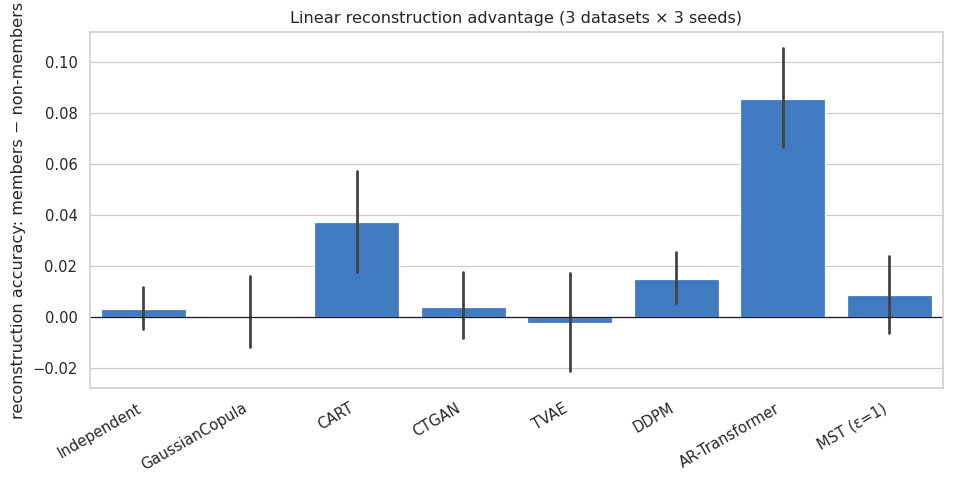

Notebook runtime: 152.6 min


,acc_mem,acc_non,advantage,adv_ci,clf_advantage,p,p_holm
generator,,,,,,,
Independent,0.6013,0.5983,0.0030,0.0107,0.0023,0.2852,1.0000
GaussianCopula,0.6231,0.6226,0.0006,0.0175,0.0166,0.6250,1.0000
CART,0.7354,0.6982,0.0372,0.0250,0.0462,0.0020,0.0156
CTGAN,0.5968,0.5929,0.0039,0.0152,0.0037,0.3379,1.0000
TVAE,0.7073,0.7096,-0.0022,0.0251,0.0070,0.6328,1.0000
DDPM,0.6951,0.6802,0.0149,0.0123,0.0273,0.0234,0.1406
AR-Transformer,0.7883,0.7029,0.0854,0.0245,0.0946,0.0020,0.0156
MST (ε=1),0.6059,0.5972,0.0087,0.0192,0.0162,0.1797,0.8984


In [7]:
tr_ = REC.groupby("generator").agg(acc_mem=("acc_mem", "mean"), acc_non=("acc_non", "mean"), advantage=("advantage", "mean"),
      adv_ci=("advantage", sa.ci_t), clf_advantage=("clf_advantage", "mean"),
      p=("advantage", lambda x: stats.wilcoxon(x, alternative="greater").pvalue if (x != 0).any() else 1.0)).reindex(REC_GENS)
tr_["p_holm"] = sa.holm(tr_.p.fillna(1)); tr_.to_csv(f"{OUT}/tables/X2_reconstruction_summary.csv")
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.barplot(data=REC, x="generator", y="advantage", order=REC_GENS, errorbar=("ci", 95), ax=ax, color="#2a78d6")
ax.axhline(0, c="k", lw=0.8); ax.set_ylabel("reconstruction accuracy: members − non-members"); ax.set_xlabel("")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right"); ax.set_title("Linear reconstruction advantage (3 datasets × 3 seeds)")
fig.savefig(f"{OUT}/figures/X2_reconstruction.png"); plt.show()
print(f"Notebook runtime: {(time.time()-T0)/60:.1f} min"); tr_.round(4)